# Logged coverage, CQL and discrete IQL

Four methods share a fixed batch per coverage/seed. No deployment score chooses an offline checkpoint. The deliberately biased behavior prefers user 1 despite user 2 priority three; this is a weighted-objective extension. An action mask does not remove distribution shift within legal actions.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/decision_lab").is_dir()
sys.path.insert(0, str(ROOT / "src"))


def read(path):
    return json.loads((ROOT / path).read_text())

## CQL pushes down relative unseen scores

In [2]:
import torch

from decision_lab.offline import conservative_penalty, expectile_loss

q = torch.tensor([[0.0, 1.0, 999.0]], requires_grad=True)
loss = conservative_penalty(q, torch.tensor([0]), torch.tensor([[True, True, False]])).sum()
loss.backward()
assert torch.allclose(q.grad, torch.tensor([[-0.7310586, 0.7310586, 0.0]]), atol=1e-6)
print(q.grad)

tensor([[-0.7311,  0.7311,  0.0000]])


## Expectile stationarity

In [3]:
v = torch.tensor([1.5], requires_grad=True)
expectile_loss(v, torch.tensor([0.0, 2.0]), 0.75).mean().backward()
assert abs(float(v.grad)) < 1e-7
print("equal-weight [0,2] expectile at tau .75 is 1.5")

equal-weight [0,2] expectile at tau .75 is 1.5


## Measured coverage and deployment gap

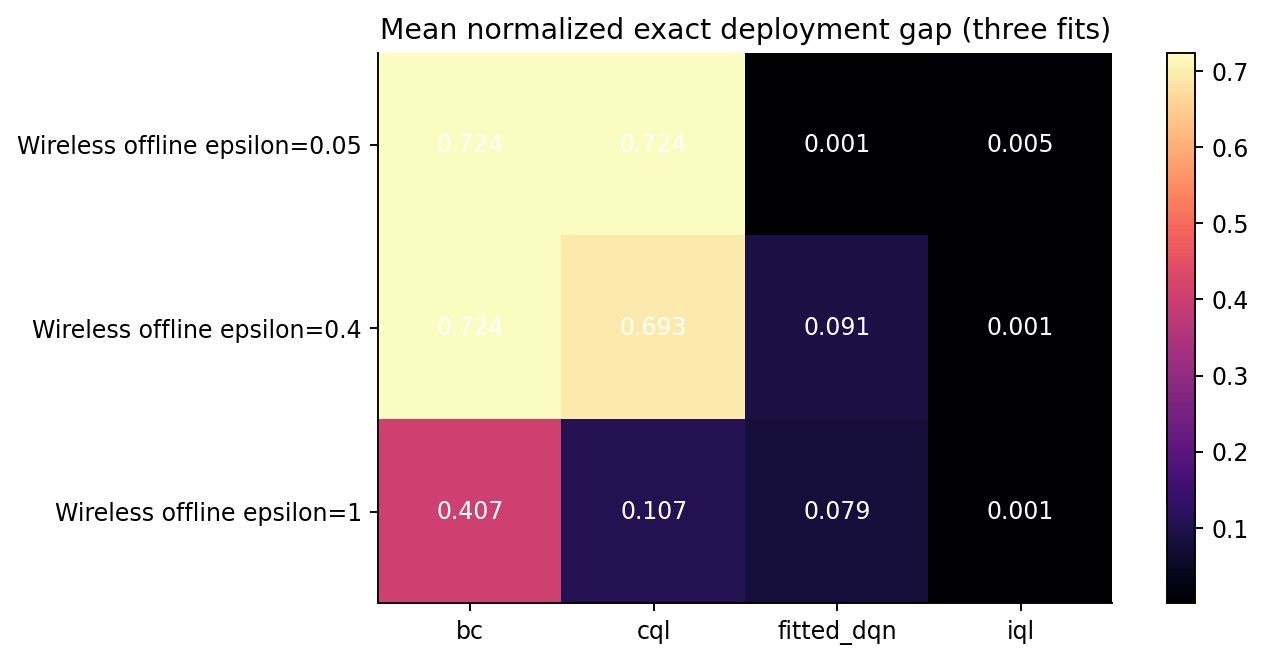

seed  visited_legal_fraction  \
behavior_epsilon recipe                                     
0.05             bc           1.0                 0.83404   
                 cql          1.0                 0.83404   
                 fitted_dqn   1.0                 0.83404   
                 iql          1.0                 0.83404   
0.40             bc           1.0                 1.00000   
                 cql          1.0                 1.00000   
                 fitted_dqn   1.0                 1.00000   
                 iql          1.0                 1.00000   
1.00             bc           1.0                 1.00000   
                 cql          1.0                 1.00000   
                 fitted_dqn   1.0                 1.00000   
                 iql          1.0                 1.00000   

                             unsupported_deployment_occupancy  \
behavior_epsilon recipe                                         
0.05             bc                                  0.001243   
                 cql                                 0.001243   
                 fitted_dqn                          0.068465   
                 iql                                 0.066403   
0.40             bc                                  0.000000   
                 cql                                 0.000000   
                 fitted_dqn                          0.000000   
                 iql                                 0.000000   
1.00             bc                                  0.000000   
                 cql                                 0.000000   
                 fitted_dqn                          0.000000   
                 iql                                 0.000000   

                             normalized_exact_policy_gap  
behavior_epsilon recipe                                   
0.05             bc                             0.723539  
                 cql                            0.723539  
                 fitted_dqn                     0.001131  
                 iql                            0.004952  
0.40             bc                             0.723539  
                 cql                            0.693327  
                 fitted_dqn                     0.090822  
                 iql                            0.001001  
1.00             bc                             0.406774  
                 cql                            0.106507  
                 fitted_dqn                     0.079220  
                 iql                            0.000754

In [4]:
from IPython.display import Image, display

display(Image(filename=str(ROOT / "assets/figures/offline_coverage.png")))
records = []
for p in (ROOT / "results/reference/offline").rglob("metrics.json"):
    m = json.loads(p.read_text())
    records.append(
        {
            k: m[k]
            for k in [
                "recipe",
                "seed",
                "behavior_epsilon",
                "visited_legal_fraction",
                "unsupported_deployment_occupancy",
                "normalized_exact_policy_gap",
            ]
        }
    )
pd.DataFrame(records).groupby(["behavior_epsilon", "recipe"]).mean(numeric_only=True)

Full fits: `decision-lab offline --seed 0` (repeat seeds 1 and 2 where applicable). See [protocol](../docs/protocol.md), [results](../docs/results.md) and [references](../docs/references.md). These cells are numerical checks and evidence readers, not replacement training budgets.